In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.spatial.distance import cdist

plt.rcParams["animation.html"] = "jshtml"

In [ ]:
def diffusion_limited_aggregation(num_particles, radius, width, height, time):
    """
    Simulates 2D Diffusion Limited Aggregation for a given number and size of particles as 
    well as the size of the box containing them

    Args:
        num_particles (int): number of particles starting in the box
        radius (float): size of each particle generated
        width (float): width of the containing box
        height (float): height of the containing box

    Returns:
        particles (2D array of floats): positions of the particles at the end of the simulation
        cluster (1D array of ints): times that each particle was added to the cluster, if at all
    """

    particles = np.stack((np.random.uniform(-width/2, width/2, num_particles),
                         np.random.uniform(-height/2, height/2, num_particles)),
                         axis=1)
    particles[0] = [0, 0]
    
    # Keep track of particles that are in the cluster: 
    #   0 if they are free
    #   t > 0 if they are in the cluster (where t is the time they were added)
    cluster = np.zeros(num_particles)
    cluster[0] = 1

    for t in range(2, time+2):
        # Move free particles
        dla_step(particles, cluster, width, height)

        # Check if free particles are close enough to cluster particles
        cluster = check_cluster(particles, cluster, radius, t)

    return particles, cluster

def dla_step(particles, cluster, width, height):
    """
    Simulates one step of a 2D Diffusion Limited Aggression process. Moves each free particle, 
    checks if they are within the boundary conditions, and moves them to the boundary if they
    go outside of it.

    Args:
        particles (2D array of floats): positions of every particle in the process
        cluster (1D array of ints): times that each particle was added to the cluster, if at all
        width (float): width of the boundary containing box
        height (float): height of the boundary containing box

    Returns:
        particles (2D array of floats): updated particles array with random movement of free moving particles
    """
    free = (cluster == 0)

    # Move each free particle
    particles[free] += np.random.uniform(-5, 5, (len(particles[free]), 2))

    # Check particles around boundary condition
    np.clip(particles[:, 0], -width/2, width/2, out = particles[:, 0])
    np.clip(particles[:, 1], -height/2, height/2, out = particles[:, 1])

    return particles

def check_cluster(particles, cluster, radius, time):
    """
    Checks which free particles intersect with cluster particles and adds them to the cluster.

    Args:
        particles (2D array of floats): positions of every particle in the process
        cluster (1D array of ints): times that each particle was added to the cluster, if at all
        radius (float): size of radius of each given particle

    Returns:
        cluster (1D array of ints): updated array of cluster times
    """
    cluster_particles = particles[cluster > 0]
    free_particles = particles[cluster == 0]

    # Compute array of distances between cluster and free particles
    dist = cdist(cluster_particles, free_particles)

    # Update cluster array if distance between any pair of 
    # cluster and free particles is less than 2 * radius
    free_index = np.where(cluster == 0)[0]
    intersect = (dist < 2 * radius).any(axis = 0)
    cluster[free_index[intersect]] = time

    return cluster

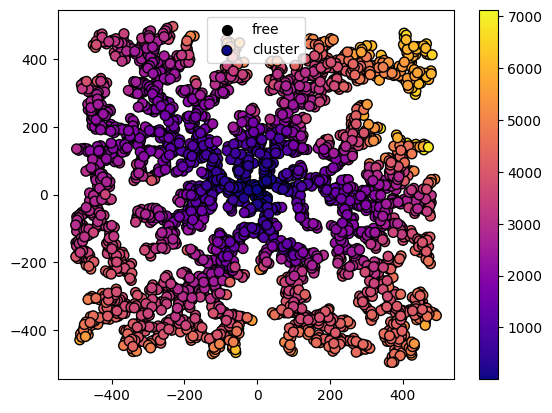

In [ ]:
HEIGHT = 1000
WIDTH = 1000
PARTICLES = 3000
RADIUS = 5
TIME = 10000

particles, cluster = diffusion_limited_aggregation(PARTICLES, RADIUS, HEIGHT, WIDTH, TIME)
free_p = particles[cluster == 0]
cluster_p = particles[cluster > 0]

plt.scatter(free_p[:, 0], free_p[:, 1], c='black', s=10*RADIUS, label='free', edgecolors='black')
plt.scatter(cluster_p[:, 0], cluster_p[:, 1], c=cluster, cmap='plasma', s=10*RADIUS, label='cluster', edgecolors='black')
plt.colorbar()
plt.legend()
plt.show()

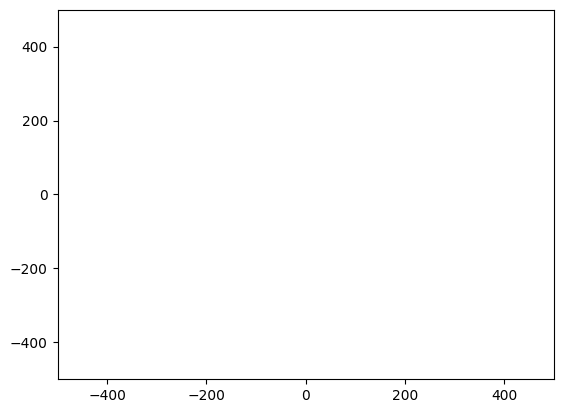

In [ ]:
tstep = 50      # Number of timesteps between each frame

fig, ax = plt.subplots()
scat = ax.scatter(cluster_p[0, 0], cluster_p[0, 1], edgecolors='black')
ax.set(xlim=[-WIDTH/2, WIDTH/2], ylim = [-HEIGHT/2, HEIGHT/2])

def update(frame):
    cluster_x = particles[(0 < cluster) & (cluster < frame*tstep)][:, 0]
    cluster_y = particles[(0 < cluster) & (cluster < frame*tstep)][:, 1]

    # Update scatter plot
    data = np.stack([cluster_x, cluster_y], axis=1)
    scat.set_offsets(data)

    return scat

ani = animation.FuncAnimation(fig=fig, func=update, frames=int(np.max(cluster))//tstep, interval=45)
ani

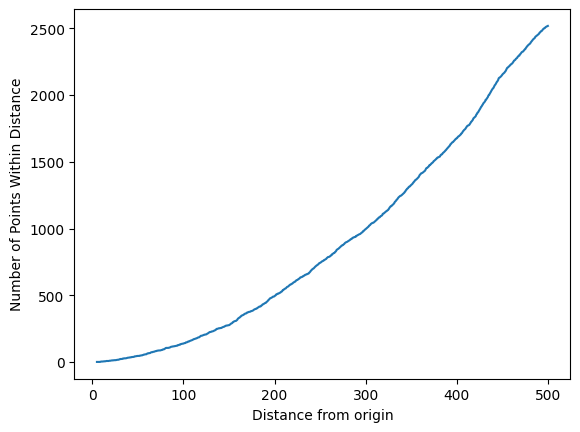

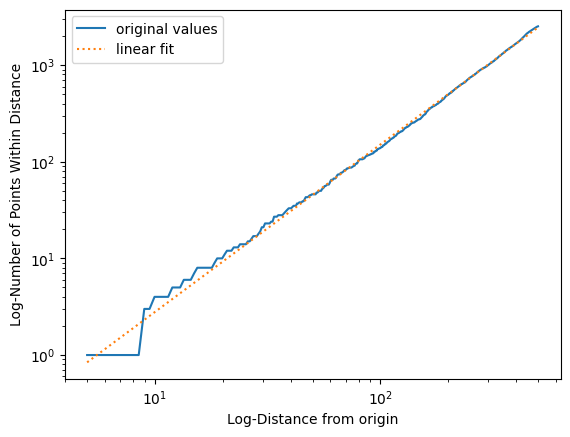

Log-Log Slope: 1.7324579588135969
Log-Log Intercept -2.961901249667247


In [ ]:
# FRACTAL DIMENSION COMPUTATION

norms = np.linalg.norm(cluster_p, axis=1)
distances = np.linspace(RADIUS, min(WIDTH, HEIGHT) / 2, 1000)
num_distances = np.zeros(1000)
for i in range(len(distances)):
    num_distances[i] = len(cluster_p[norms < distances[i]])

plt.plot(distances, num_distances)
plt.xlabel('Distance from origin')
plt.ylabel('Number of Points Within Distance')
plt.show()

np_m, np_b = np.linalg.lstsq(np.stack((np.log(distances), np.ones(len(distances))), axis=1), np.log(num_distances), rcond=None)[0]

plt.loglog(distances, num_distances, label='original values')
plt.loglog(distances, np.exp(np_m * np.log(distances) + np_b), linestyle='dotted', label='linear fit')
plt.xlabel('Log-Distance from origin')
plt.ylabel('Log-Number of Points Within Distance')
plt.legend()
plt.show()

print("Log-Log Slope:", np_m)
print("Log-Log Intercept", np_b)